# Municipal Solid Waste Generated, Nonthaburi Province

**Data:** `data/raw/community.csv` — municipal solid waste (tonnes) per local government per month, Buddhist Era 2563–2567 (2020–2024) (2,655 rows, 6 districts)

This is the project's **main dataset** — the web app uses `data/clean/clean_community.csv` as backup data, and other notebooks use it as the denominator for recycling rates/cost per tonne

**Steps**
1. Load, explore and convert data types
2. Fix outliers in 3 tiers (wrong unit → a specific anomaly → outliers relative to each one's own median)
3. Save `clean_community.csv`
4. Charts: distribution, yearly/monthly trends, by district/local government, **waste per person**

# ปริมาณขยะมูลฝอยชุมชนที่เกิดขึ้น จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/community.csv` — ปริมาณขยะมูลฝอยชุมชน (ตัน) ราย อปท. รายเดือน พ.ศ. 2563–2567 (2,655 แถว, 6 อำเภอ)

ข้อมูลชุดนี้เป็น **ชุดหลัก** ของโปรเจกต์ — เว็บแอปใช้ `data/clean/clean_community.csv` เป็นข้อมูลสำรอง และ notebook อื่นใช้เป็นตัวหารในการคำนวณอัตรารีไซเคิล/ต้นทุนต่อตัน

**ขั้นตอน**
1. โหลด สำรวจ และแปลงชนิดข้อมูล
2. แก้ค่าผิดปกติ 3 ชั้น (หน่วยผิด → จุดผิดปกติเฉพาะ → ค่าโดดเทียบ median ของตัวเอง)
3. บันทึก `clean_community.csv`
4. กราฟ: การกระจาย, แนวโน้มรายปี/รายเดือน, รายอำเภอ/อปท., **ขยะต่อหัวประชากร**

**Import libraries** — `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for charts

**นำเข้าไลบรารี** — `pandas`, `numpy` สำหรับจัดการข้อมูล และ `matplotlib`, `seaborn` สำหรับวาดกราฟ

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sbs

**Load the raw data** from `../data/raw/community.csv`

**โหลดข้อมูลดิบ** จาก `../data/raw/community.csv`

In [2]:
df = pd.read_csv('../data/raw/community.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท.,ขยะมูลฝอยชุมชน(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,189.12
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,123.84
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,154.2
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,232.13
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,642.67
...,...,...,...,...,...,...
2650,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,750.775
2651,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,716.215
2652,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,"1,098.55"
2653,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,อบต.บางไผ่,441.42


**Look at the first 5 rows** with `head()` to confirm the data is in the right format

**ดูตัวอย่าง 5 แถวแรก** ด้วย `head()` เพื่อยืนยันว่าข้อมูลอยู่ในรูปแบบที่ถูกต้อง

In [3]:
df.head()

,ปี,เดือน,จังหวัด,อำเภอ,อปท.,ขยะมูลฝอยชุมชน(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,189.12
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,123.84
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,154.2
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,232.13
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,642.67


**Count missing values** in each column with `isnull().sum()` — 0 in every column means there are no gaps

**นับค่าสูญหาย (Missing values)** ในแต่ละคอลัมน์ด้วย `isnull().sum()` — ถ้าเป็น 0 ทุกคอลัมน์แปลว่าไม่มีช่องว่าง

In [4]:
df.isnull().sum()

ปี                     0
เดือน                  0
จังหวัด                0
อำเภอ                  0
อปท.                   0
ขยะมูลฝอยชุมชน(ตัน)    0
dtype: int64

**Check for duplicate rows** with `duplicated().sum()` — 0 means no rows are identical in every column, so nothing needs to be removed

**ตรวจแถวซ้ำ** ด้วย `duplicated().sum()` — ถ้าได้ 0 แปลว่าไม่มีแถวที่ข้อมูลเหมือนกันทุกคอลัมน์ ไม่ต้องลบอะไร

In [5]:
df.duplicated().sum()

np.int64(0)

**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ปี                   2655 non-null   int64 
 1   เดือน                2655 non-null   object
 2   จังหวัด              2655 non-null   object
 3   อำเภอ                2655 non-null   object
 4   อปท.                 2655 non-null   object
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   object
dtypes: int64(1), object(5)
memory usage: 124.6+ KB


**Convert the waste column to numbers** — remove `,` and convert to `float`

**แปลงคอลัมน์ขยะเป็นตัวเลข** — ลบเครื่องหมาย `,` แล้วแปลงเป็น `float`

In [7]:
df['ขยะมูลฝอยชุมชน(ตัน)'] = df['ขยะมูลฝอยชุมชน(ตัน)'].str.replace(',', '').astype(float)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ปี                   2655 non-null   int64  
 1   เดือน                2655 non-null   object 
 2   จังหวัด              2655 non-null   object 
 3   อำเภอ                2655 non-null   object 
 4   อปท.                 2655 non-null   object 
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 124.6+ KB


**Convert text columns to `category`** (month, province, district, local government) to save memory and speed up `groupby`

**แปลงคอลัมน์ข้อความเป็น `category`** (เดือน, จังหวัด, อำเภอ, อปท.) เพื่อประหยัดหน่วยความจำและ `groupby` เร็วขึ้น

In [8]:
for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   ปี                   2655 non-null   int64   
 1   เดือน                2655 non-null   category
 2   จังหวัด              2655 non-null   category
 3   อำเภอ                2655 non-null   category
 4   อปท.                 2655 non-null   category
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   float64 
dtypes: category(4), float64(1), int64(1)
memory usage: 54.1 KB


**Outlier fix, tier 1 – wrong unit**

Values **above 100,000 tonnes per month** are impossible for a single local government, so they are assumed to have been entered in **kilograms** instead of tonnes → divided by 1,000 to convert back to tonnes

**แก้ค่าผิดปกติชั้นที่ 1 – หน่วยผิด**

ค่าที่ **เกิน 100,000 ตันต่อเดือน** เป็นไปไม่ได้สำหรับ อปท. เดียว จึงสันนิษฐานว่ากรอกเป็น **กิโลกรัม** แทนตัน → หารด้วย 1,000 เพื่อแปลงกลับเป็นตัน

In [9]:
df.loc[df["ขยะมูลฝอยชุมชน(ตัน)"] > 100_000, "ขยะมูลฝอยชุมชน(ตัน)"] = df.loc[df["ขยะมูลฝอยชุมชน(ตัน)"] > 100_000, "ขยะมูลฝอยชุมชน(ตัน)"] / 1000

**Outlier fix, tier 2 – a specific anomaly at Pak Kret City Municipality**

A value of ~72,135 tonnes was found, many times higher than normal months, so:
1. Find Pak Kret's median from normal months (< 20,000 tonnes)
2. Replace values > 70,000 with that median

**แก้ค่าผิดปกติชั้นที่ 2 – จุดผิดปกติเฉพาะของเทศบาลนครปากเกร็ด**

พบค่าที่พุ่งไปถึง ~72,135 ตัน ซึ่งสูงกว่าเดือนปกติหลายเท่า จึง:
1. หา median ของปากเกร็ดจากเดือนที่ปกติ (< 20,000 ตัน)
2. แทนค่าที่ > 70,000 ด้วย median นั้น

In [10]:
# 1. Find the normal median of Pak Kret City Municipality (excluding the problem months)
# 1. หาค่ากลาง (Median) ปกติของเทศบาลนครปากเกร็ด (ไม่รวมเดือนที่มีปัญหา)
pakkret_normal_median = df[(df['อปท.'] == 'เทศบาลนครปากเกร็ด') & (df['ขยะมูลฝอยชุมชน(ตัน)'] < 20000)]['ขยะมูลฝอยชุมชน(ตัน)'].median()

# 2. Fix only the point that jumped to 72,135, setting it back to the normal median
# 2. แก้ไขเฉพาะจุดที่ดีดไป 72,135 ให้กลับมาเป็นค่ากลางปกติ
df.loc[(df['อปท.'] == 'เทศบาลนครปากเกร็ด') & (df['ขยะมูลฝอยชุมชน(ตัน)'] > 70000), 'ขยะมูลฝอยชุมชน(ตัน)'] = pakkret_normal_median

**Outlier fix, tier 3 – outliers relative to each one's own median**

- Compute the median per local government (fair to both small subdistrict administrative organizations and large municipalities)
- If a month's value is **> 4 times its own median and > 1,000 tonnes** → replace it with the median
- Remove the helper column `median_waste` (this cell correctly assigns back with `df = df.drop(...)`)

**แก้ค่าผิดปกติชั้นที่ 3 – ค่าโดดเทียบกับ median ของตัวเอง**

- คำนวณ median ราย อปท. (ยุติธรรมกับทั้ง อบต. เล็กและเทศบาลใหญ่)
- ถ้าค่าเดือนใด **> 4 เท่าของ median ตัวเอง และ > 1,000 ตัน** → แทนด้วย median
- ลบคอลัมน์ช่วยคำนวณ `median_waste` ออก (เซลล์นี้ assign กลับ `df = df.drop(...)` ถูกต้องแล้ว)

In [11]:
# 2. Compute the median of each local government separately
# This gives small subdistrict organizations and large municipalities detection thresholds that are fair to their size
# 2. คำนวณหาค่ากลาง (Median) ของแต่ละ อปท. แยกจากกัน
# วิธีนี้ทำให้ อบต.เล็ก และ เทศบาลใหญ่ มีเกณฑ์ตรวจจับที่เป็นธรรมกับขนาดตัวเอง
df['median_waste'] = df.groupby('อปท.')['ขยะมูลฝอยชุมชน(ตัน)'].transform('median')

# 3. Condition: if the waste value in a month is "more than 4 times its own median"
# and more than 1,000 tonnes (to avoid adjusting very small local governments too much)
# 3. ตั้งเงื่อนไข: ถ้าค่าขยะในเดือนนั้น "สูงเกิน 4 เท่าของค่ากลางตัวเอง" 
# และมีปริมาณมากกว่า 1,000 ตัน (เพื่อป้องกันการปรับค่าใน อปท. ที่เล็กมากๆ จนเกินไป)
condition = (df['ขยะมูลฝอยชุมชน(ตัน)'] > df['median_waste'] * 4) & (df['ขยะมูลฝอยชุมชน(ตัน)'] > 1000)

# Check the count before fixing
# เช็คยอดก่อนแก้
outlier_count = df[condition].shape[0]
print(f"พบข้อมูลโดดผิดปกติที่ต้องแก้ไขทั้งหมด: {outlier_count} แถว")

# 4. Replace (clean) those outliers with the local government's normal median
# 4. ทำการแทนที่ (Clean) ค่าที่โดดเหล่านั้นด้วยค่า Median ปกติของ อปท. นั้นๆ
df.loc[condition, 'ขยะมูลฝอยชุมชน(ตัน)'] = df.loc[condition, 'median_waste']

# Drop the helper column so the file is clean
# ลบคอลัมน์ที่สร้างมาช่วยคำนวณทิ้งเพื่อให้ไฟล์สะอาด
df = df.drop(columns=['median_waste'])

พบข้อมูลโดดผิดปกติที่ต้องแก้ไขทั้งหมด: 63 แถว


/var/folders/jp/qywn4qv17q56wh6qhsrjcmk80000gn/T/ipykernel_47257/945341290.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['median_waste'] = df.groupby('อปท.')['ขยะมูลฝอยชุมชน(ตัน)'].transform('median')


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [12]:
df.to_csv('../data/clean/clean_community.csv')

**Chart setup** — uses seaborn's `whitegrid` theme and picks the first available Thai font

**ตั้งค่ากราฟ** — ใช้ธีม `whitegrid` ของ seaborn และเลือกฟอนต์ภาษาไทยตัวแรกที่มีในเครื่อง

In [13]:

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

# Thai font setup
# ตั้งค่าฟอนต์ภาษาไทย
thai_fonts = ['Tahoma', 'Leelawadee UI', 'Leelawadee', 'TH Sarabun New', 'Browallia New', 'Cordia New']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')

plt.rcParams['font.family'] = thai_font
plt.rcParams['axes.unicode_minus'] = False

print(f'ใช้ฟอนต์: {thai_font}')


ใช้ฟอนต์: Tahoma


**Histogram: distribution of waste per local government per month**

Each bar is the number of rows (local government-months) whose waste falls in that range. Red line = mean, orange line = median

**What it shows:** the chart is strongly right-skewed — most local governments produce a few hundred tonnes/month, but a few large municipalities are very high, so **the mean is much higher than the median**. The median is the better representative of a "typical local government"

**Histogram: การกระจายของปริมาณขยะต่อ อปท. ต่อเดือน**

แต่ละแท่งคือจำนวนแถว (อปท.-เดือน) ที่มีปริมาณขยะอยู่ในช่วงนั้น เส้นแดง = ค่าเฉลี่ย, เส้นส้ม = มัธยฐาน

**สิ่งที่เห็น:** กราฟเบ้ขวามาก (right-skewed) — อปท. ส่วนใหญ่มีขยะไม่กี่ร้อยตัน/เดือน แต่มีเทศบาลใหญ่ไม่กี่แห่งที่สูงมาก ทำให้ **ค่าเฉลี่ยสูงกว่ามัธยฐานมาก** จึงควรใช้มัธยฐานเป็นตัวแทน "อปท. ทั่วไป"

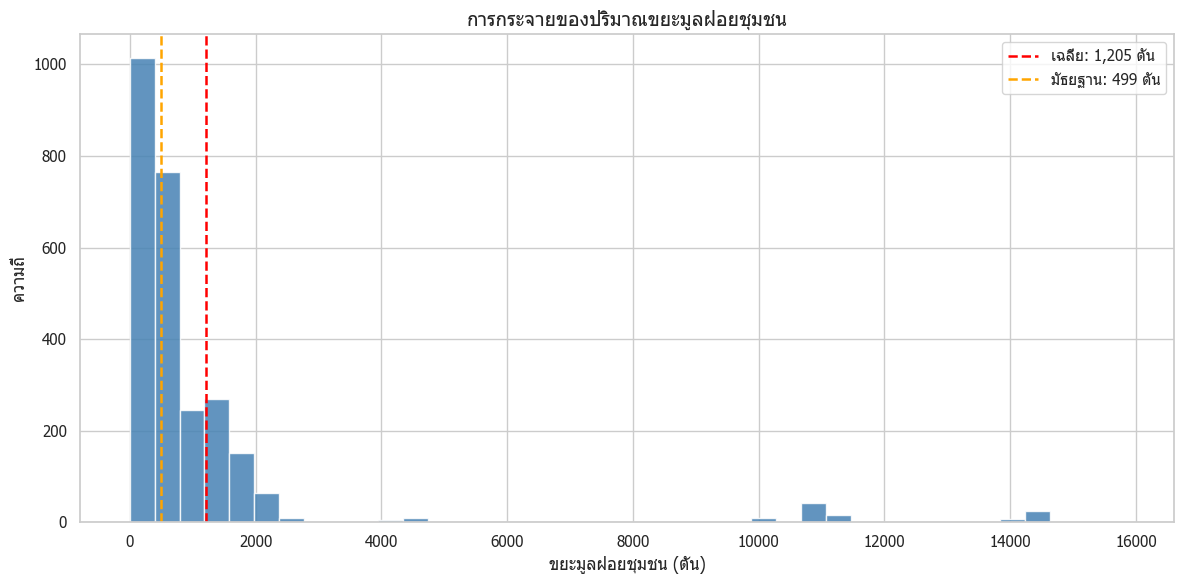

In [14]:

# Histogram: distribution of municipal solid waste
# Histogram: การกระจายของปริมาณขยะมูลฝอยชุมชน
col = 'ขยะมูลฝอยชุมชน(ตัน)'
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df[col], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.8, label=f"เฉลี่ย: {df[col].mean():,.0f} ตัน")
ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=1.8, label=f"มัธยฐาน: {df[col].median():,.0f} ตัน")
ax.set_title('การกระจายของปริมาณขยะมูลฝอยชุมชน', fontsize=14)
ax.set_xlabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.set_ylabel('ความถี่')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


**Boxplot by year** — the box is the middle 50% of the data (Q1–Q3), the red line inside is the median, and the dots above are values far from the group (mostly large municipalities, not data errors)

Use it to see whether the distribution changes from year to year

**Boxplot รายปี** — กล่องคือช่วง 50% กลางของข้อมูล (Q1–Q3), เส้นแดงในกล่องคือมัธยฐาน, จุดด้านบนคือค่าที่สูงผิดจากกลุ่ม (ส่วนใหญ่คือเทศบาลขนาดใหญ่ ไม่ใช่ข้อมูลผิด)

ใช้ดูว่าการกระจายของแต่ละปีเปลี่ยนไปหรือไม่

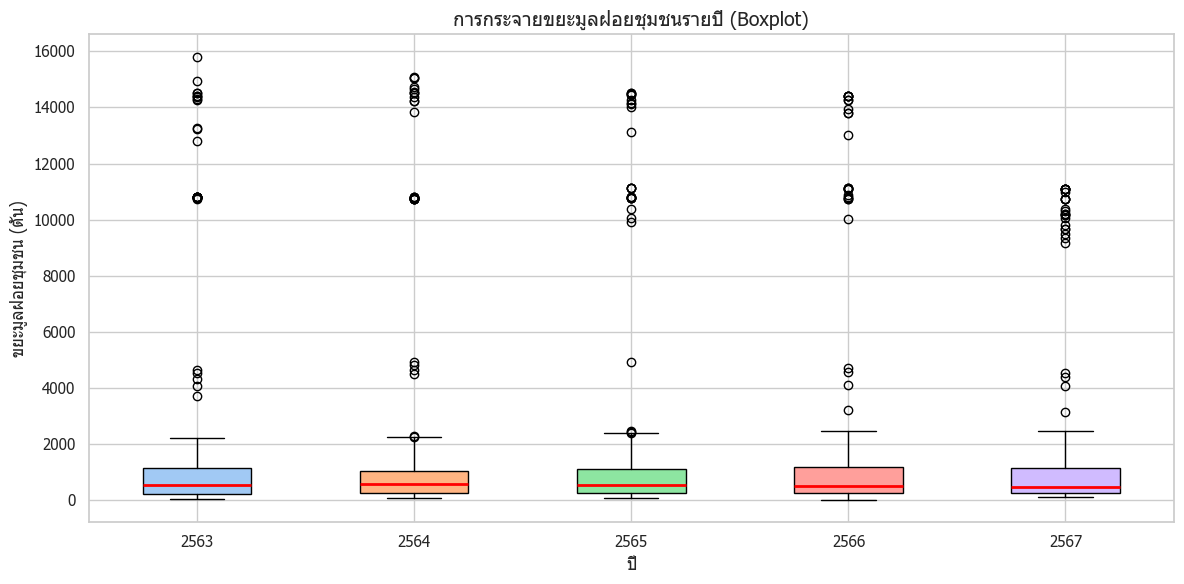

In [15]:

# Boxplot: distribution of municipal solid waste by year
# Boxplot: การกระจายขยะมูลฝอยชุมชนรายปี
years = sorted(df['ปี'].unique())
data_by_year = [df[df['ปี'] == y]['ขยะมูลฝอยชุมชน(ตัน)'].values for y in years]
fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot(data_by_year, labels=years, patch_artist=True,
                medianprops=dict(color='red', linewidth=2))
colors = sns.color_palette('pastel', len(years))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax.set_title('การกระจายขยะมูลฝอยชุมชนรายปี (Boxplot)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
plt.tight_layout()
plt.show()


**Line chart: total waste per year** — sums every local government and every month to show the province's overall trend

**กราฟเส้น: ปริมาณขยะรวมรายปี** — รวมทุก อปท. ทุกเดือน ดูแนวโน้มภาพรวมของจังหวัด

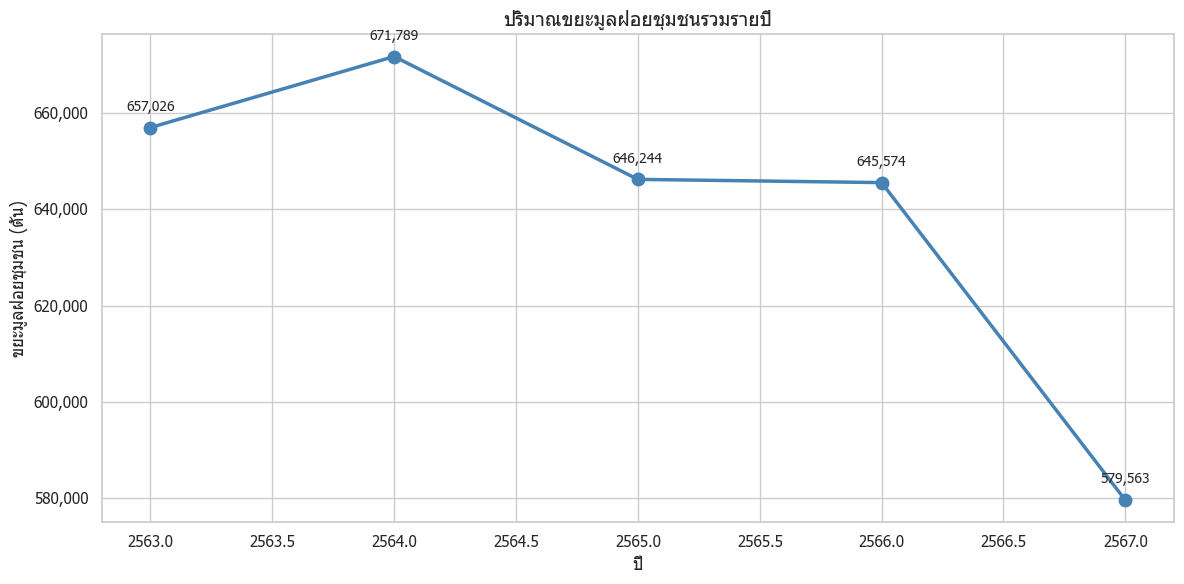

In [16]:

# Line Chart: total municipal solid waste per year
# Line Chart: ปริมาณขยะมูลฝอยชุมชนรวมรายปี
yearly = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum()
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly.index, yearly.values, marker='o', linewidth=2.5, color='steelblue', markersize=9)
for x, y in zip(yearly.index, yearly.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=10)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรวมรายปี', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Bar chart: monthly average** — the average per local government for each month (averaged across all years), used to see seasonal patterns

**กราฟแท่ง: ค่าเฉลี่ยรายเดือน** — ค่าเฉลี่ยต่อ อปท. ของแต่ละเดือน (เฉลี่ยข้ามทุกปี) ใช้ดูรูปแบบตามฤดูกาล

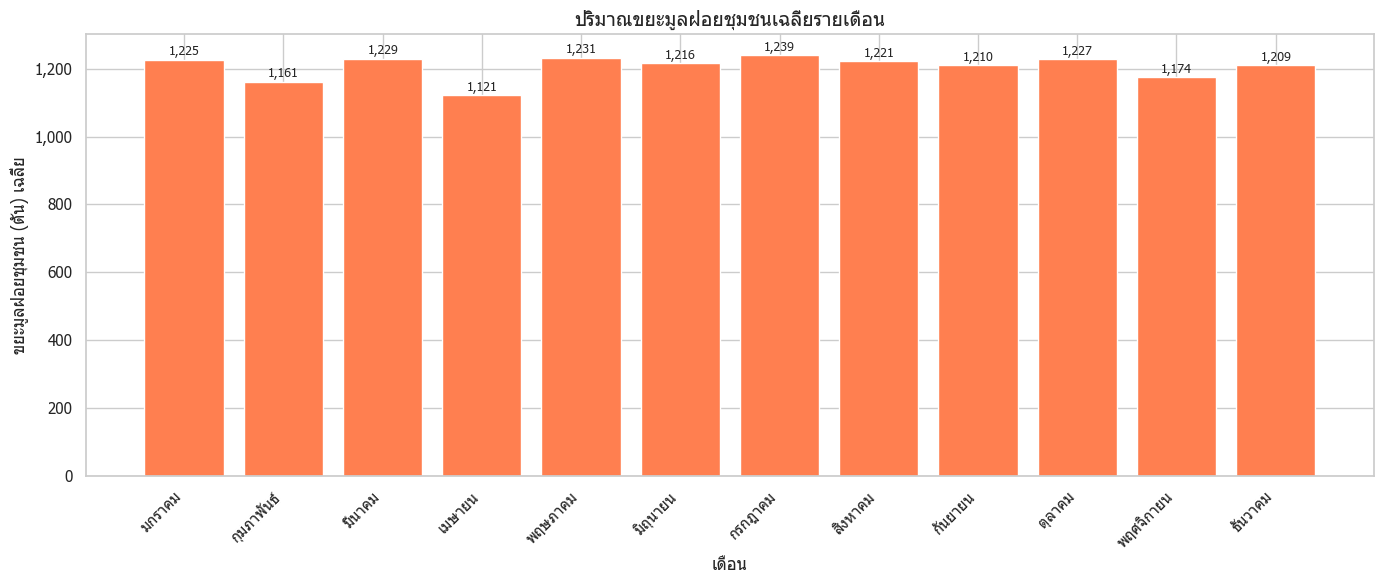

In [17]:

# Bar Chart: average municipal solid waste per month
# Bar Chart: ปริมาณขยะมูลฝอยชุมชนเฉลี่ยรายเดือน
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly_avg = df.groupby('เดือน', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].mean().reindex(month_order)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(12), monthly_avg.values, color='coral', edgecolor='white')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
for i, v in enumerate(monthly_avg.values):
    ax.text(i, v + 5, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนเฉลี่ยรายเดือน', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) เฉลี่ย')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Heatmap year × month** — the province total for each month of each year, darker = more waste. Use it to spot unusual months and compare the same month across years

**Heatmap ปี × เดือน** — ยอดรวมทั้งจังหวัดของแต่ละเดือนในแต่ละปี สีเข้ม = ขยะมาก ใช้หาเดือนที่ผิดปกติและเทียบเดือนเดียวกันข้ามปี

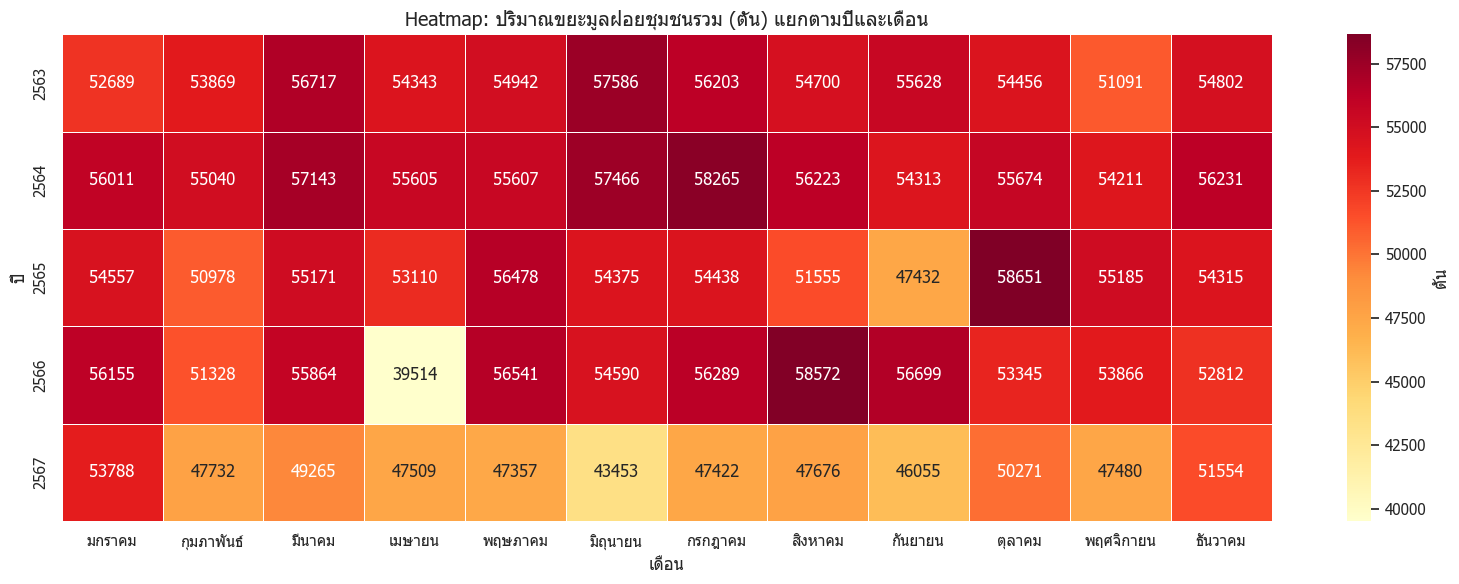

In [18]:

# Heatmap: total municipal solid waste by year and month
# Heatmap: ปริมาณขยะมูลฝอยชุมชนรวม แยกตามปีและเดือน
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
pivot = (df.groupby(['ปี', 'เดือน'], observed=True)['ขยะมูลฝอยชุมชน(ตัน)']
         .sum().unstack('เดือน').reindex(columns=month_order))
fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'ตัน'})
ax.set_title('Heatmap: ปริมาณขยะมูลฝอยชุมชนรวม (ตัน) แยกตามปีและเดือน', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('ปี')
plt.tight_layout()
plt.show()


**Bar chart: total by district** (5 years combined), sorted from largest to smallest

**กราฟแท่ง: ยอดรวมรายอำเภอ** (รวม 5 ปี) เรียงจากมากไปน้อย

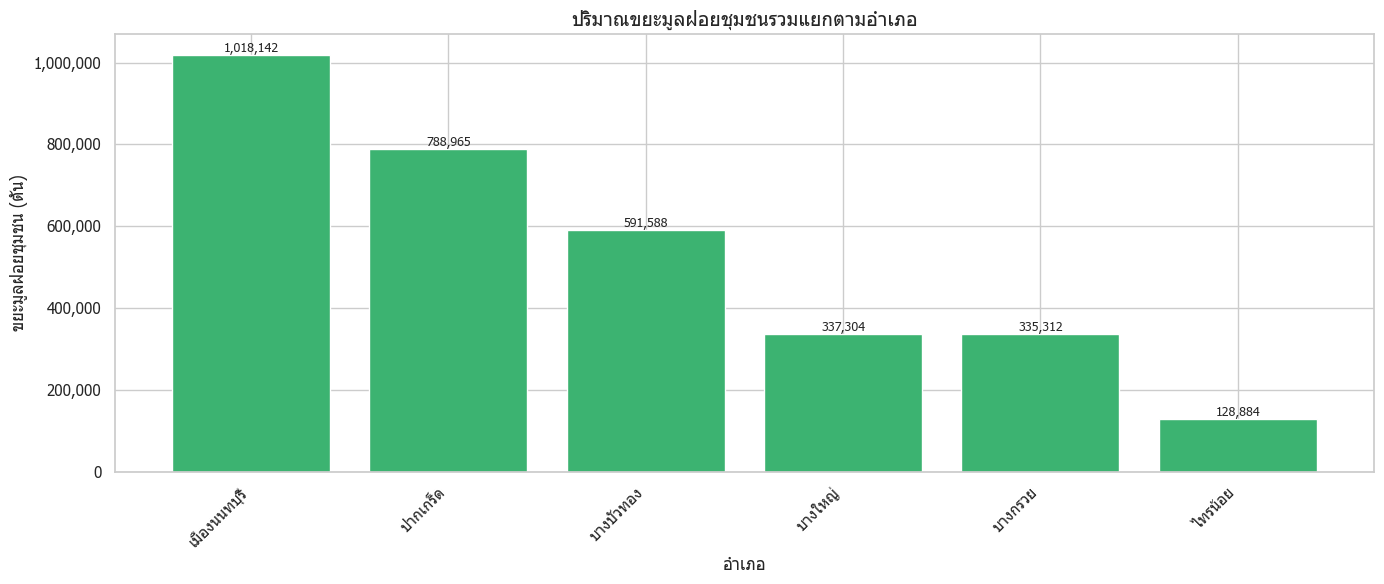

In [19]:

# Bar Chart: total municipal solid waste by district
# Bar Chart: ปริมาณขยะมูลฝอยชุมชนรวมแยกตามอำเภอ
district_total = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(len(district_total)), district_total.values, color='mediumseagreen', edgecolor='white')
ax.set_xticks(range(len(district_total)))
ax.set_xticklabels(district_total.index, rotation=45, ha='right')
for i, v in enumerate(district_total.values):
    ax.text(i, v + 200, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรวมแยกตามอำเภอ', fontsize=14)
ax.set_xlabel('อำเภอ')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Horizontal bar chart: top 10 local governments by total waste** — shows how concentrated the waste is

**กราฟแท่งแนวนอน: 10 อปท. ที่มีขยะรวมสูงสุด** — แสดงการกระจุกตัวของปริมาณขยะ

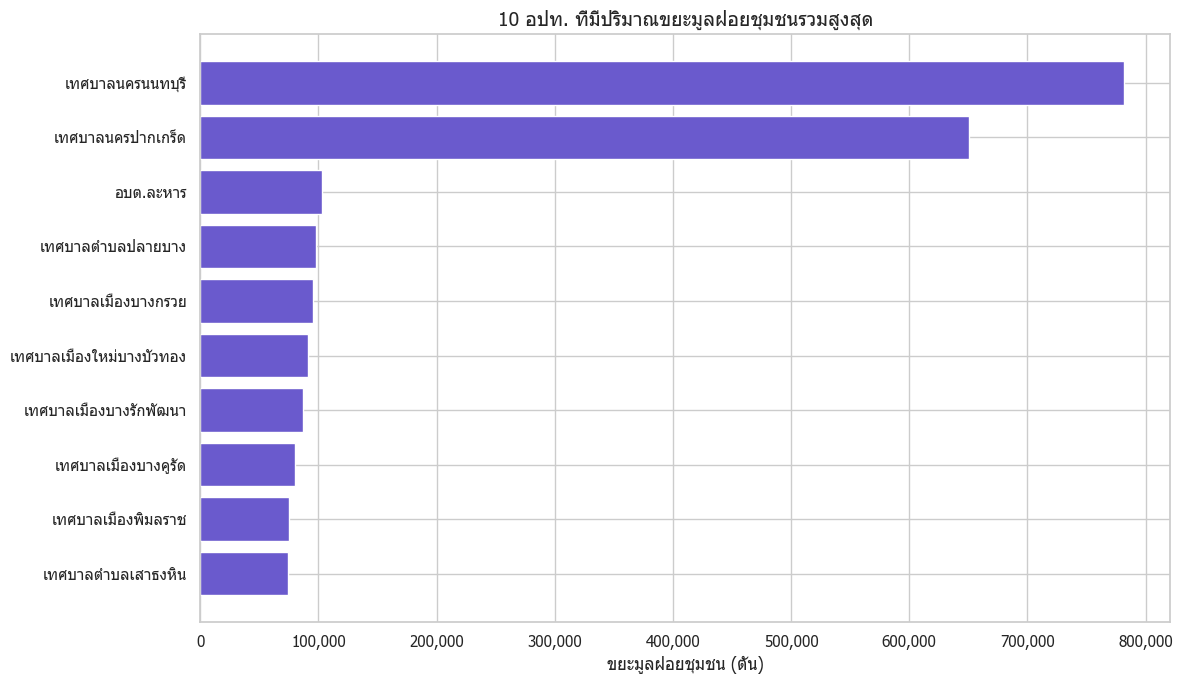

In [20]:

# Horizontal Bar: top 10 local governments by waste
# Horizontal Bar: 10 อปท. ที่มีปริมาณขยะสูงสุด
top10 = df.groupby('อปท.', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(range(len(top10)), top10.values, color='slateblue', edgecolor='white')
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10.index)
ax.set_title('10 อปท. ที่มีปริมาณขยะมูลฝอยชุมชนรวมสูงสุด', fontsize=14)
ax.set_xlabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Bar chart: average per row by district** — the average local government-month in each district (districts with a few large local governments have high averages)

**กราฟแท่ง: ค่าเฉลี่ยต่อแถวรายอำเภอ** — ค่าเฉลี่ยของ อปท.-เดือน ในแต่ละอำเภอ (อำเภอที่มี อปท. ใหญ่ไม่กี่แห่งจะมีค่าเฉลี่ยสูง)

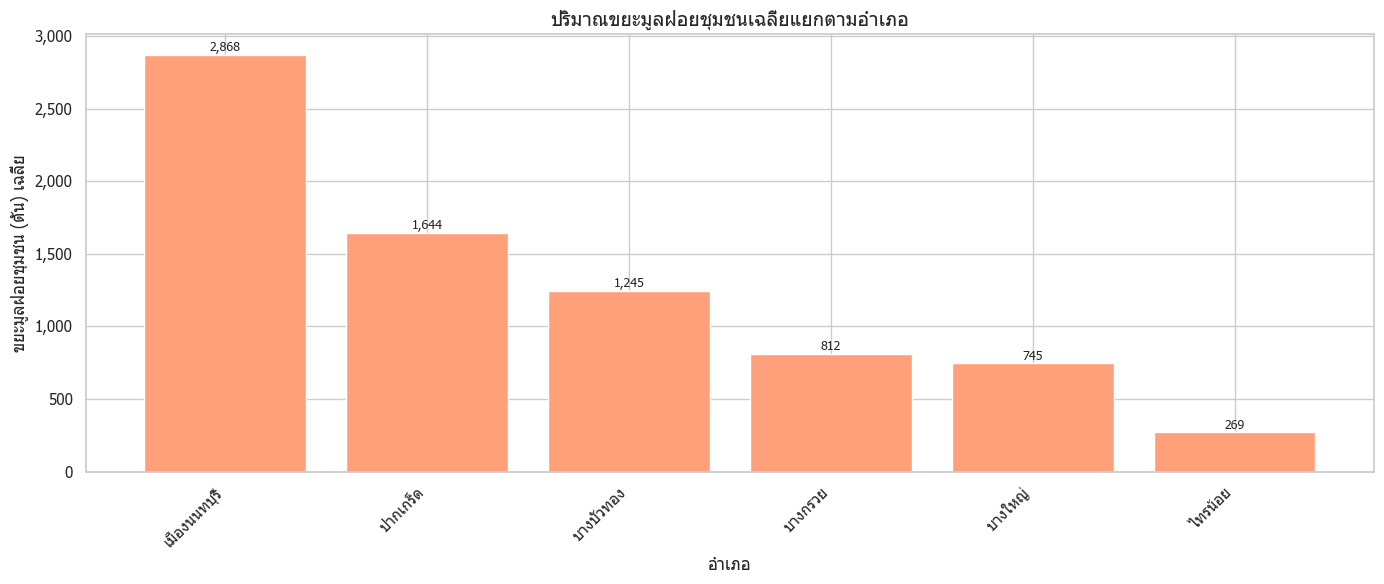

In [21]:

# Bar Chart: average municipal solid waste by district
# Bar Chart: ปริมาณขยะมูลฝอยชุมชนเฉลี่ยแยกตามอำเภอ
district_avg = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(len(district_avg)), district_avg.values, color='lightsalmon', edgecolor='white')
ax.set_xticks(range(len(district_avg)))
ax.set_xticklabels(district_avg.index, rotation=45, ha='right')
for i, v in enumerate(district_avg.values):
    ax.text(i, v + 5, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนเฉลี่ยแยกตามอำเภอ', fontsize=14)
ax.set_xlabel('อำเภอ')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) เฉลี่ย')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Pie chart: share of waste by district** — each slice is the % of the province total

> Fixed: this cell used to raise an error because the argument `pctdistance=0.8` had been mistyped as just `=0.8`

**แผนภูมิวงกลม: สัดส่วนขยะแยกตามอำเภอ** — แต่ละชิ้นคือ % ของยอดรวมทั้งจังหวัด

> แก้ไขแล้ว: เดิมเซลล์นี้ error เพราะพิมพ์อาร์กิวเมนต์ `pctdistance=0.8` ตกหล่นเหลือแค่ `=0.8`

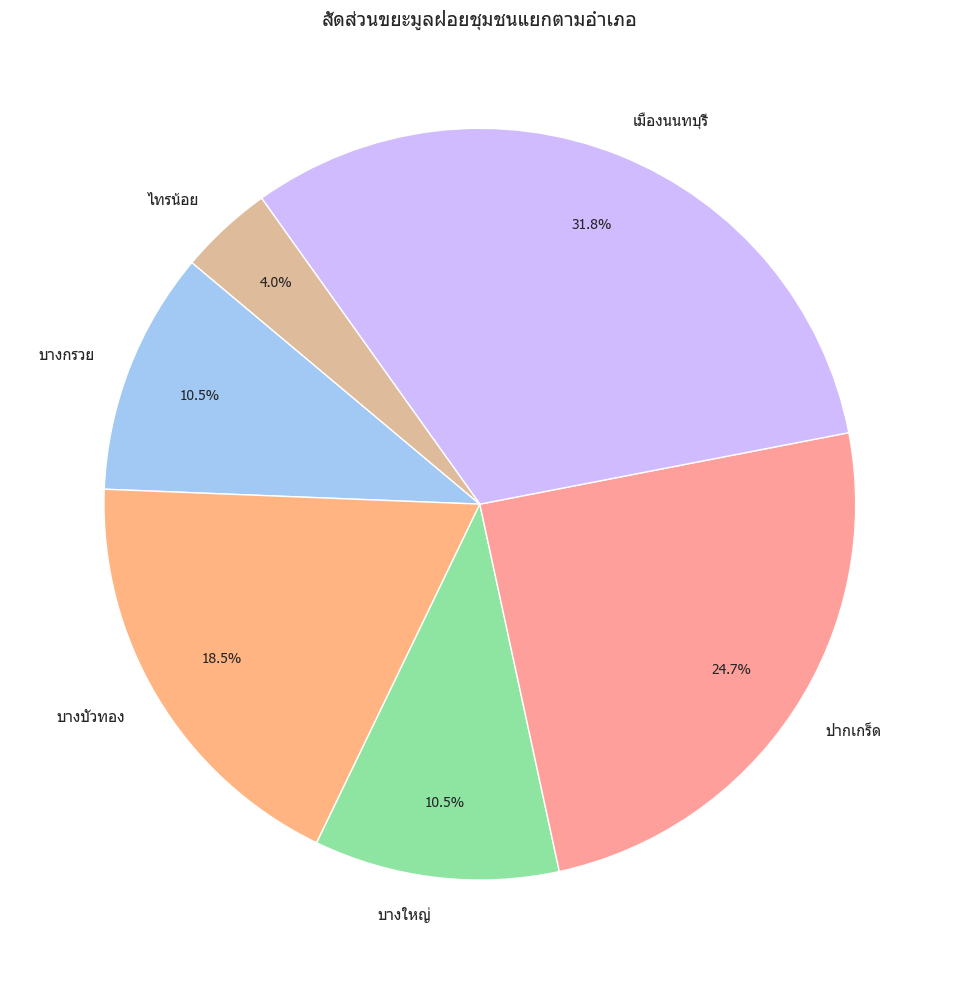

In [22]:

# Pie Chart: share of municipal solid waste by district
# Pie Chart: สัดส่วนขยะมูลฝอยชุมชนแยกตามอำเภอ
district_total = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum()
fig, ax = plt.subplots(figsize=(10, 10))
wedges, texts, autotexts = ax.pie(
    district_total, labels=district_total.index, autopct='%1.1f%%',
    startangle=140, pctdistance=0.8,
    colors=sns.color_palette('pastel', len(district_total))
)
for t in autotexts:
    t.set_fontsize(10)
ax.set_title('สัดส่วนขยะมูลฝอยชุมชนแยกตามอำเภอ', fontsize=14)
plt.tight_layout()
plt.show()


**YoY bar chart: change from the previous year (%)** — `pct_change()` computes (this year − last year) ÷ last year × 100. Green bars = increase, red = decrease

**กราฟแท่ง YoY: การเปลี่ยนแปลงเทียบปีก่อน (%)** — `pct_change()` คำนวณ (ปีนี้ − ปีก่อน) ÷ ปีก่อน × 100 แท่งเขียว = เพิ่ม, แดง = ลด

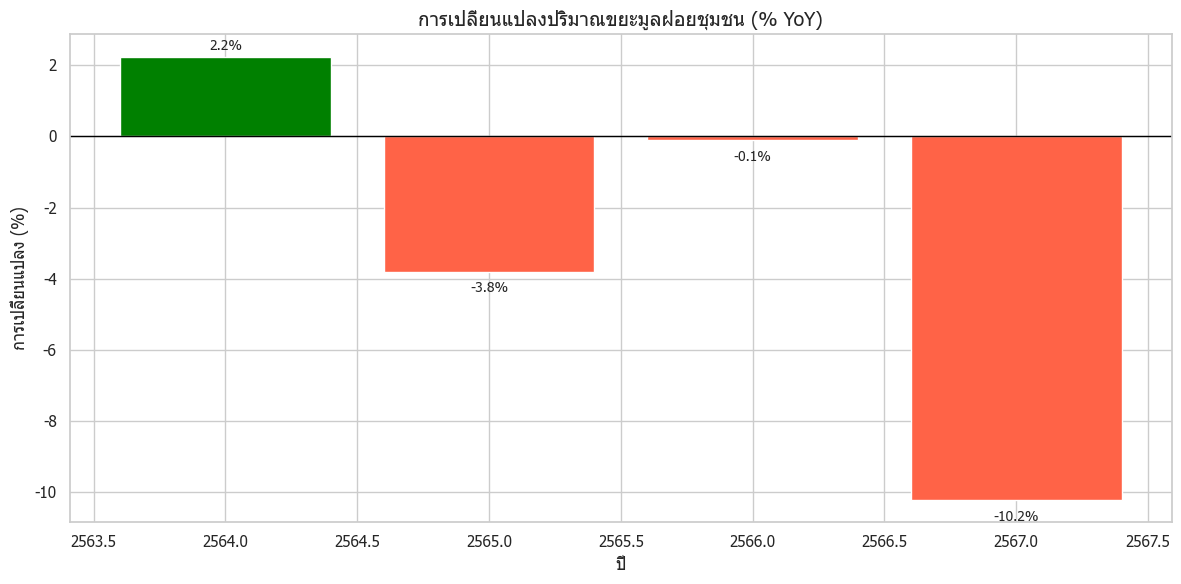

In [23]:

# YoY: change in municipal solid waste (% Year-over-Year)
# YoY: การเปลี่ยนแปลงปริมาณขยะมูลฝอยชุมชน (% Year-over-Year)
yearly = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum()
yoy = yearly.pct_change() * 100
colors = ['green' if v >= 0 else 'tomato' for v in yoy.dropna()]
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(yoy.dropna().index, yoy.dropna().values, color=colors, edgecolor='white')
ax.axhline(0, color='black', linewidth=1)
for x, y in zip(yoy.dropna().index, yoy.dropna().values):
    ax.annotate(f'{y:.1f}%', (x, y), textcoords='offset points',
                xytext=(0, 5 if y >= 0 else -15), ha='center', fontsize=10)
ax.set_title('การเปลี่ยนแปลงปริมาณขยะมูลฝอยชุมชน (% YoY)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('การเปลี่ยนแปลง (%)')
plt.tight_layout()
plt.show()


**Area chart: cumulative waste** — `cumsum()` keeps adding up the totals, showing all the waste generated since 2563 (2020)

**กราฟพื้นที่: ปริมาณขยะสะสม (Cumulative)** — `cumsum()` บวกยอดสะสมไปเรื่อย ๆ แสดงปริมาณขยะทั้งหมดที่เกิดขึ้นตั้งแต่ปี 2563

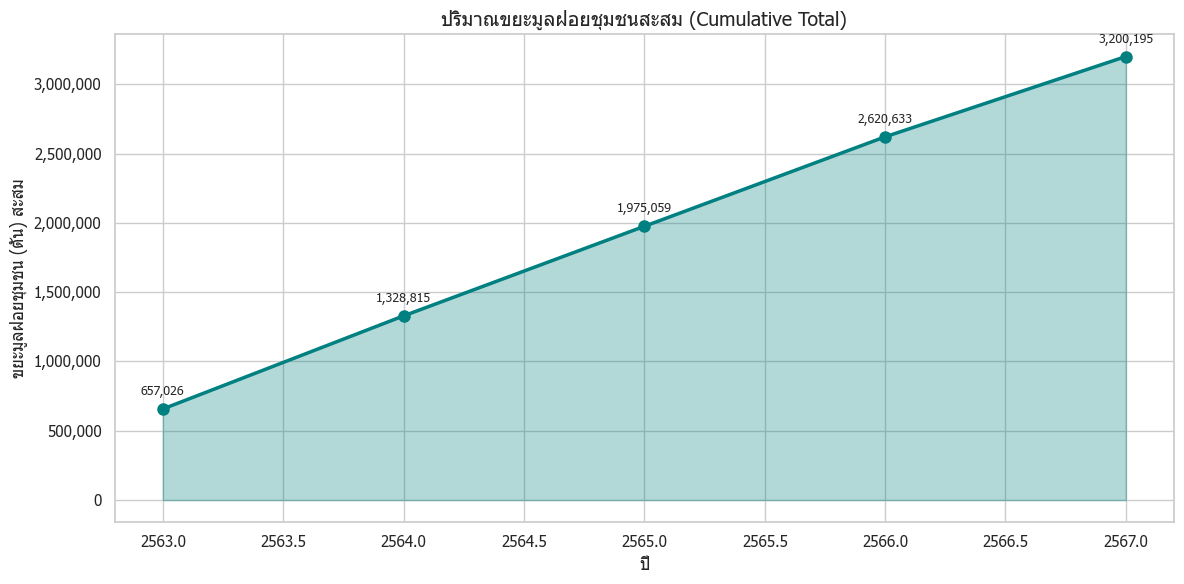

In [24]:

# Cumulative: cumulative municipal solid waste
# Cumulative: ปริมาณขยะมูลฝอยชุมชนสะสม
yearly_cumsum = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum().cumsum()
fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(yearly_cumsum.index, yearly_cumsum.values, alpha=0.3, color='teal')
ax.plot(yearly_cumsum.index, yearly_cumsum.values, marker='o', color='teal', linewidth=2.5, markersize=8)
for x, y in zip(yearly_cumsum.index, yearly_cumsum.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนสะสม (Cumulative Total)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) สะสม')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Grouped bar chart: min / mean / max per year** (per local government-month) — the gap between the mean and the max shows how different large local governments are from typical ones

**กราฟแท่งกลุ่ม: ค่าต่ำสุด / เฉลี่ย / สูงสุด รายปี** (ต่อ อปท.-เดือน) — ช่องว่างระหว่างค่าเฉลี่ยกับค่าสูงสุดแสดงว่า อปท. ใหญ่ต่างจาก อปท. ทั่วไปมากแค่ไหน

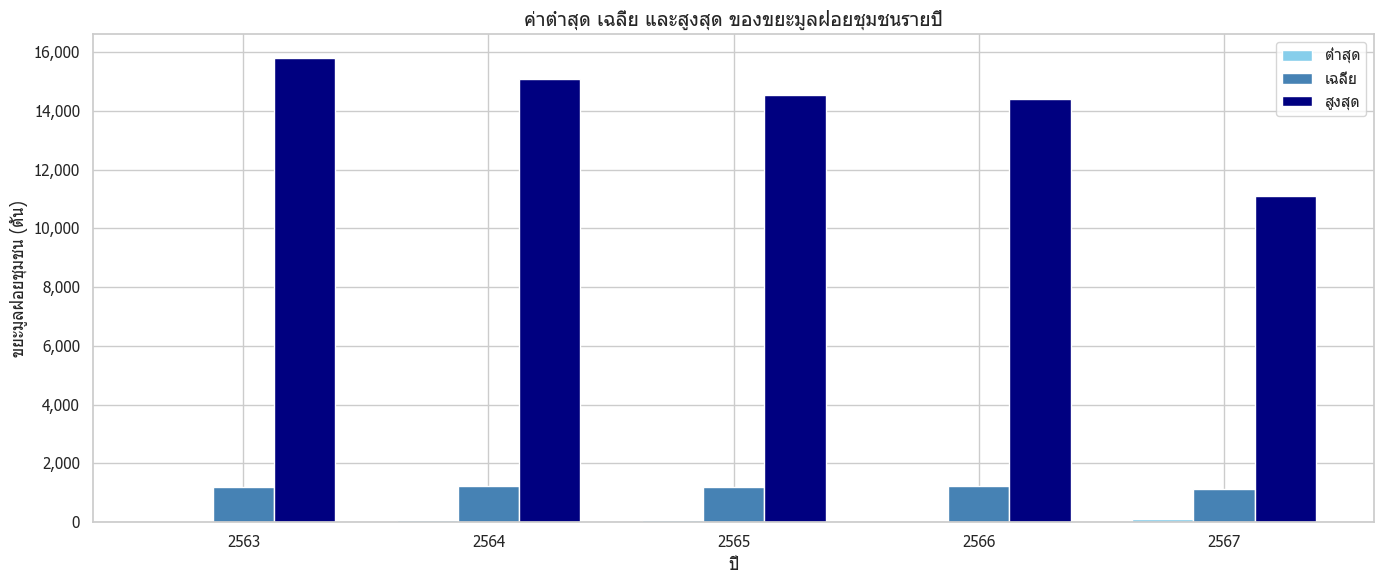

In [25]:

# Grouped Bar: min, mean and max of municipal solid waste per year
# Grouped Bar: ค่าต่ำสุด เฉลี่ย สูงสุด ของขยะมูลฝอยชุมชนรายปี
yearly_stats = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].agg(['min', 'mean', 'max'])
x = range(len(yearly_stats))
width = 0.25
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar([i - width for i in x], yearly_stats['min'],  width=width, label='ต่ำสุด',  color='skyblue',   edgecolor='white')
ax.bar(list(x),                 yearly_stats['mean'], width=width, label='เฉลี่ย', color='steelblue',  edgecolor='white')
ax.bar([i + width for i in x], yearly_stats['max'],  width=width, label='สูงสุด', color='navy',       edgecolor='white')
ax.set_xticks(list(x))
ax.set_xticklabels(yearly_stats.index)
ax.set_title('ค่าต่ำสุด เฉลี่ย และสูงสุด ของขยะมูลฝอยชุมชนรายปี', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


**Bar chart: share of each month (% of the overall total)** — if every month were equal each would be ~8.3%; months above that are high-waste periods

**กราฟแท่ง: สัดส่วนของแต่ละเดือน (% ของยอดรวมทั้งหมด)** — ถ้าทุกเดือนเท่ากันจะได้ ~8.3% ต่อเดือน เดือนที่สูงกว่านี้คือช่วงที่ขยะมาก

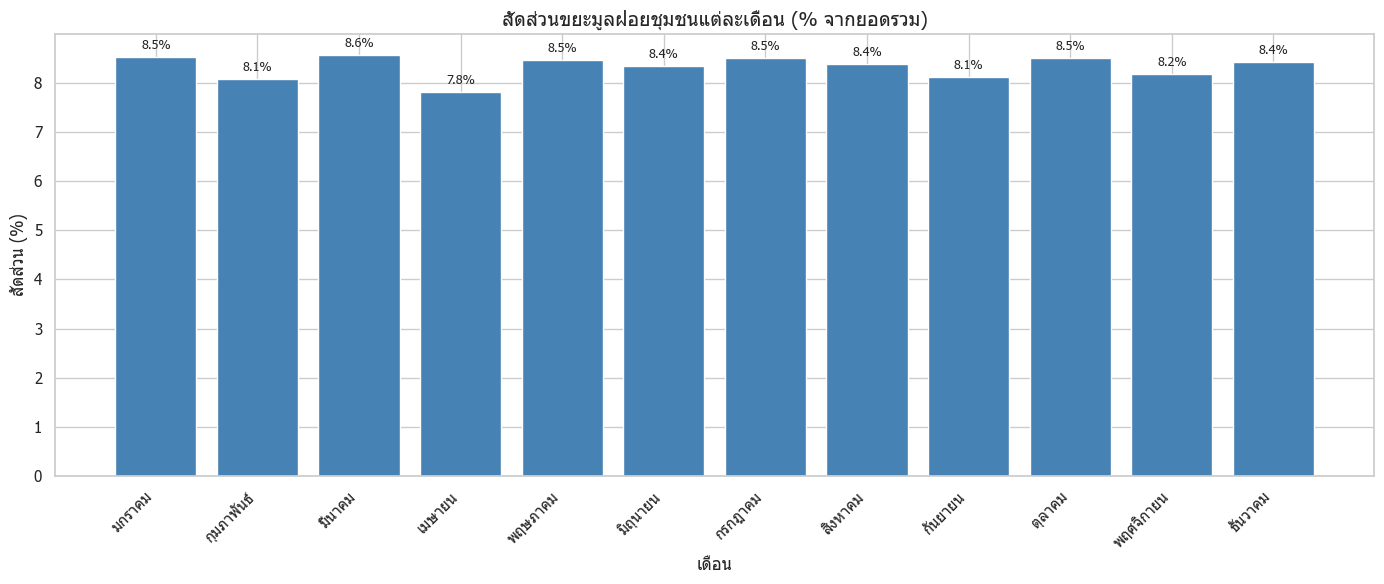

In [26]:

# Bar Chart: share of municipal solid waste per month (% of the overall total)
# Bar Chart: สัดส่วนขยะมูลฝอยชุมชนแต่ละเดือน (% จากยอดรวมทั้งหมด)
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly_total = df.groupby('เดือน', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().reindex(month_order)
pct = monthly_total / monthly_total.sum() * 100
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(12), pct.values, color='steelblue', edgecolor='white')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
for i, v in enumerate(pct.values):
    ax.text(i, v + 0.1, f'{v:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_title('สัดส่วนขยะมูลฝอยชุมชนแต่ละเดือน (% จากยอดรวม)', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('สัดส่วน (%)')
plt.tight_layout()
plt.show()


---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [27]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [28]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(2655, 6)


,ปี,เดือน,จังหวัด,อำเภอ,อปท.,ขยะมูลฝอยชุมชน(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,189.12
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,123.84
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,154.20
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,232.13
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,642.67


### 2.2 Stacked bar chart: yearly totals by district
**What it does:** builds a pivot table (rows = year, columns = district) and draws the bars stacked on top of each other

**How to read it:** the full bar height = that year's total, and each color is one district's share — it shows "which district the rise/fall in the total comes from"

### 2.2 กราฟแท่งซ้อน (Stacked Bar): ยอดรายปีแยกตามอำเภอ
**ทำอะไร:** สร้างตาราง pivot (แถว = ปี, คอลัมน์ = อำเภอ) แล้ววาดแท่งซ้อนกัน

**วิธีอ่าน:** ความสูงทั้งแท่ง = ยอดรวมของปีนั้น, แต่ละสีคือส่วนของแต่ละอำเภอ ช่วยให้เห็นว่า "การเพิ่ม/ลดของยอดรวม มาจากอำเภอไหน"

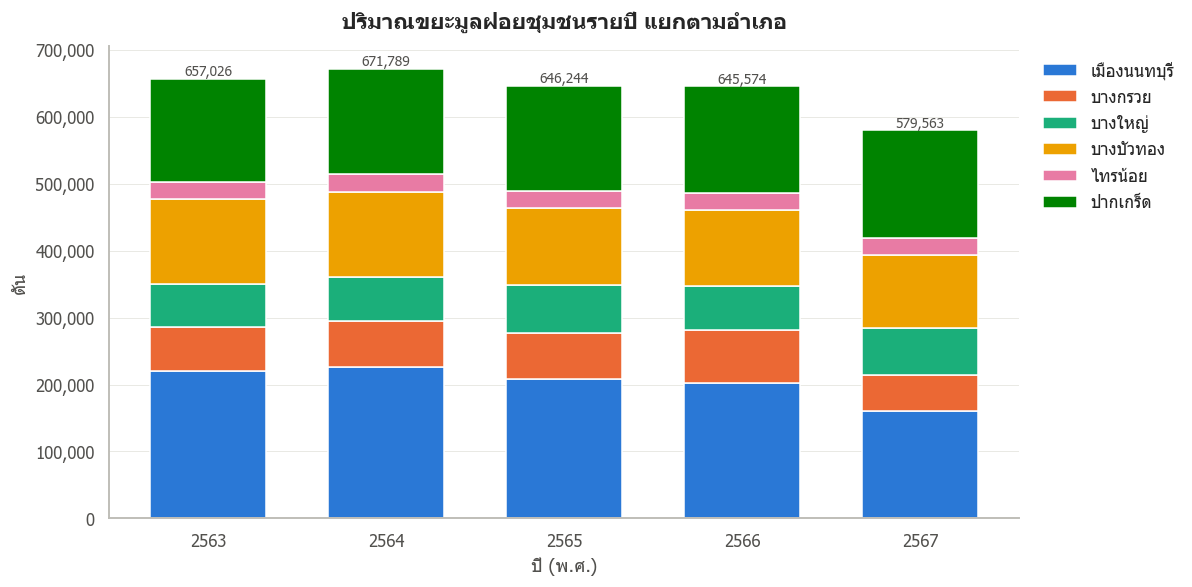

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด
ปี,,,,,,
2563,220395.7,66265.2,63133.5,126685.7,26634.5,153911.1
2564,226054.6,68638.2,66184.0,126877.5,26365.7,157669.3
2565,208917.9,67761.6,72120.9,115571.4,24837.3,157034.8
2566,202158.5,79275.6,65721.8,112939.6,25503.6,159974.6
2567,160615.4,53371.8,70144.1,109514.0,25542.6,160374.9


In [29]:
col = 'ขยะมูลฝอยชุมชน(ตัน)'
pivot = (viz.pivot_table(index='ปี', columns='อำเภอ', values=col, aggfunc='sum')
            .reindex(columns=[d for d in DIST_ORDER if d in set(viz['อำเภอ'])]))

fig, ax = plt.subplots(figsize=(11, 5.5))
totals = stacked_bar(ax, pivot)
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรายปี แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
pivot.round(1)

### 2.3 Multi-line chart: monthly trend by district (60 months)
**How to read it:** each line is one district (district color, name at the end of the line). See how each district's seasonality or trend differs, and whether there are months with unusual drops (possibly missing data)

### 2.3 กราฟเส้นหลายเส้น: แนวโน้มรายเดือนแยกตามอำเภอ (60 เดือน)
**วิธีอ่าน:** แต่ละเส้นคือหนึ่งอำเภอ (สีประจำอำเภอ, ชื่อกำกับที่ปลายเส้น) ดูว่าแต่ละอำเภอมีฤดูกาลหรือแนวโน้มต่างกันอย่างไร และมีเดือนที่ตกลงผิดปกติ (อาจเป็นข้อมูลขาด) หรือไม่

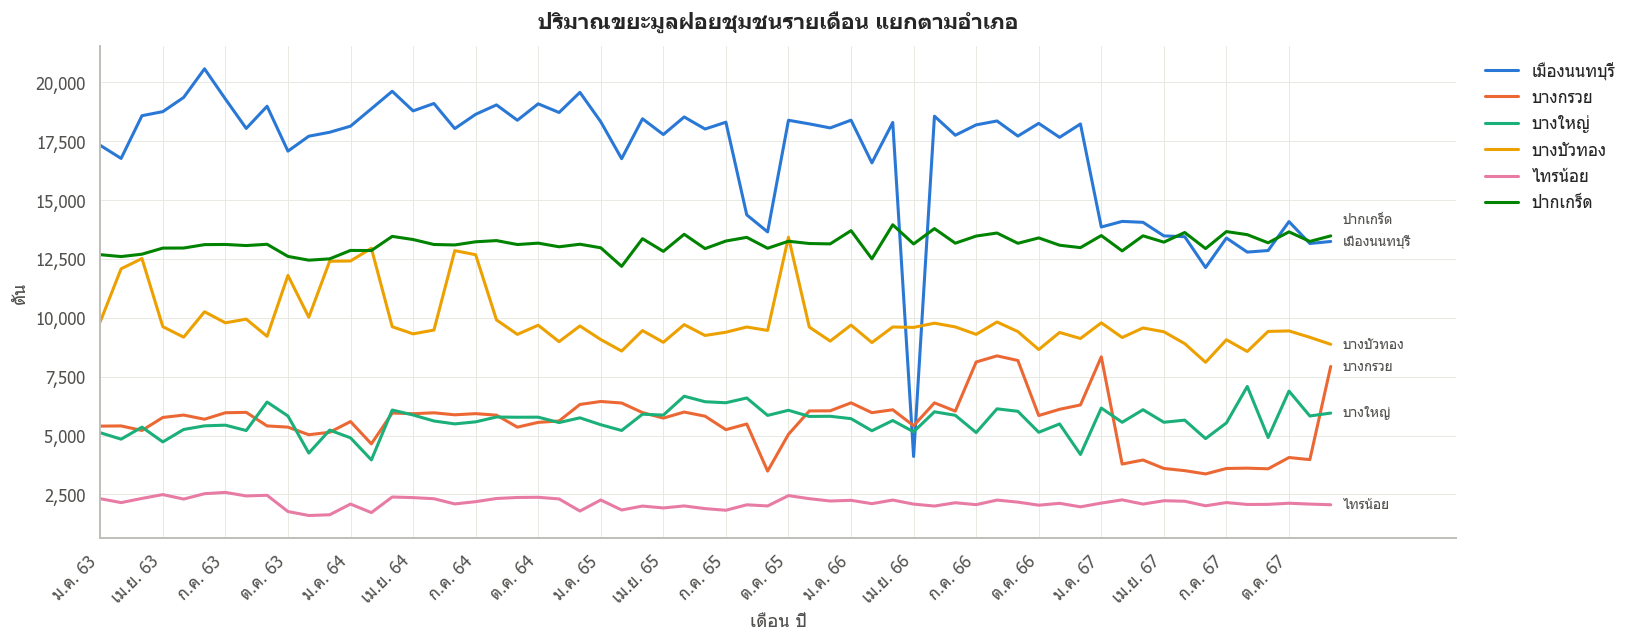

In [30]:
viz['เดือนที่'] = viz['เดือน'].map({m: i + 1 for i, m in enumerate(MONTHS)})
ts = viz.pivot_table(index=['ปี', 'เดือนที่'], columns='อำเภอ', values='ขยะมูลฝอยชุมชน(ตัน)', aggfunc='sum').sort_index()
ts = ts[[d for d in DIST_ORDER if d in ts.columns]]
labels = [f'{MONTHS_SHORT[m - 1]} {str(y)[-2:]}' for y, m in ts.index]
pos = np.arange(len(ts))
fig, ax = plt.subplots(figsize=(15, 6))
for d in ts.columns:
    ax.plot(pos, ts[d], linewidth=2, color=DIST_COLOR[d], label=d)
ax.set_xticks(pos[::3], labels[::3], rotation=45, ha='right')
ax.set_xlim(0, len(pos) + 5)
end_labels(ax, pos[-1], [(d, ts[d].iloc[-1]) for d in ts.columns])
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรายเดือน แยกตามอำเภอ')
ax.set_xlabel('เดือน ปี'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()

### 2.4 Boxplot by district: waste per local government per month
**How to read it:** each district's box shows the range of waste among its local governments. A very tall box = local governments of very different sizes (e.g. a city municipality alongside small subdistrict organizations). A log scale is used so both small and large local governments are visible

### 2.4 Boxplot รายอำเภอ: การกระจายของขยะต่อ อปท. ต่อเดือน
**วิธีอ่าน:** กล่องของแต่ละอำเภอแสดงช่วงขยะของ อปท. ในอำเภอนั้น อำเภอที่กล่องยาวมาก = มี อปท. ขนาดต่างกันมาก (เช่น มีเทศบาลนครอยู่ร่วมกับ อบต. เล็ก ๆ) ใช้สเกล log เพื่อให้เห็นทั้ง อปท. เล็กและใหญ่

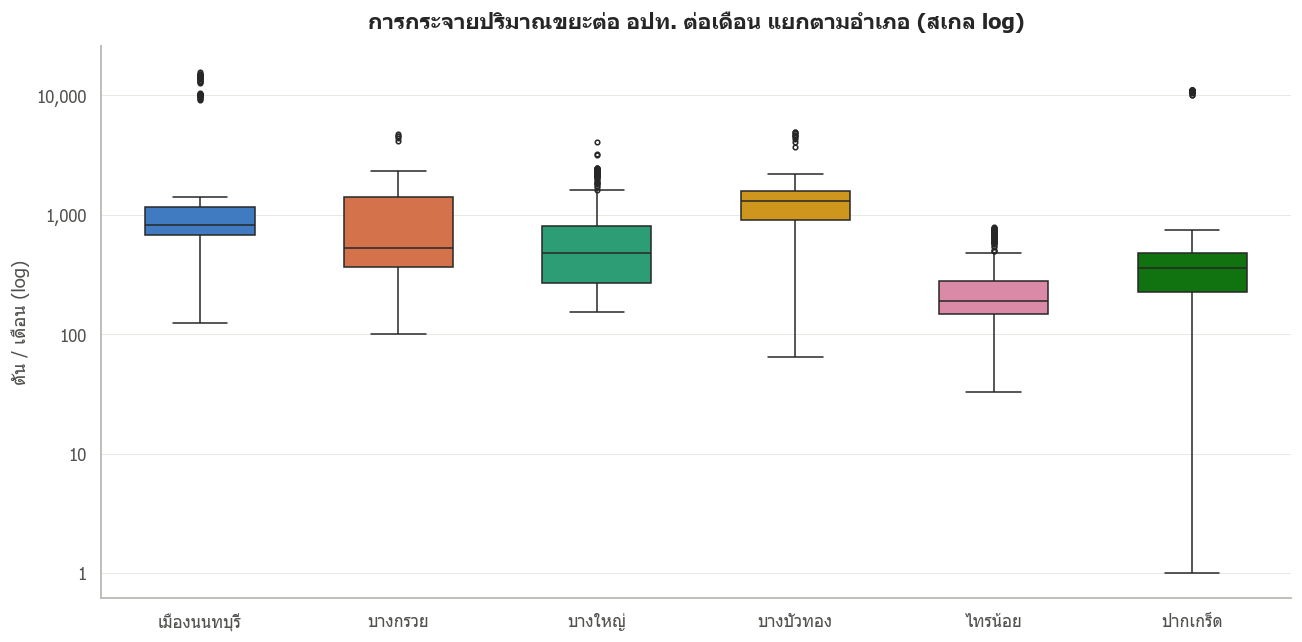

In [31]:
order = [d for d in DIST_ORDER if d in set(viz['อำเภอ'])]
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=viz[viz['ขยะมูลฝอยชุมชน(ตัน)'] > 0], x='อำเภอ', y='ขยะมูลฝอยชุมชน(ตัน)', order=order,
            palette=[DIST_COLOR[d] for d in order], width=0.55, fliersize=3, linewidth=1, ax=ax)
ax.set_yscale('log'); ax.yaxis.set_major_formatter(fmt_k)
ax.grid(axis='x', visible=False)
ax.set_title('การกระจายปริมาณขยะต่อ อปท. ต่อเดือน แยกตามอำเภอ (สเกล log)')
ax.set_xlabel(''); ax.set_ylabel('ตัน / เดือน (log)')
plt.tight_layout(); plt.show()

### 2.5 Line chart: waste per person (kg/person/day) by district
**What it does:** uses the population data (`clean_population.csv`) as the denominator

`waste per person = total yearly waste (tonnes) × 1,000 ÷ population ÷ 365`  → unit: kg/person/day

Only available for 2563–2566 (2020–2023), the years with population data

**How to read it:** a measure that **can be compared fairly across districts** (independent of district size). Thailand's national average is about 1.1–1.2 kg/person/day; districts far above that may be job/shopping hubs with an unregistered daytime population (workers not registered as residents in the area)

### 2.5 กราฟเส้น: ขยะต่อหัวประชากร (กิโลกรัม/คน/วัน) รายอำเภอ
**ทำอะไร:** นำข้อมูลประชากร (`clean_population.csv`) มาเป็นตัวหาร

`ขยะต่อหัว = ขยะรวมทั้งปี (ตัน) × 1,000 ÷ ประชากร ÷ 365`  → หน่วย กก./คน/วัน

ใช้ได้เฉพาะปี 2563–2566 (ปีที่มีข้อมูลประชากร)

**วิธีอ่าน:** เป็นตัวชี้วัดที่ **เทียบข้ามอำเภอได้ยุติธรรม** (ไม่ขึ้นกับขนาดอำเภอ) ค่าเฉลี่ยของประเทศไทยอยู่ราว 1.1–1.2 กก./คน/วัน อำเภอที่สูงกว่านี้มาก อาจเป็นแหล่งงาน/ห้างที่มีประชากรแฝง (คนทำงานที่ไม่มีทะเบียนบ้านในพื้นที่)

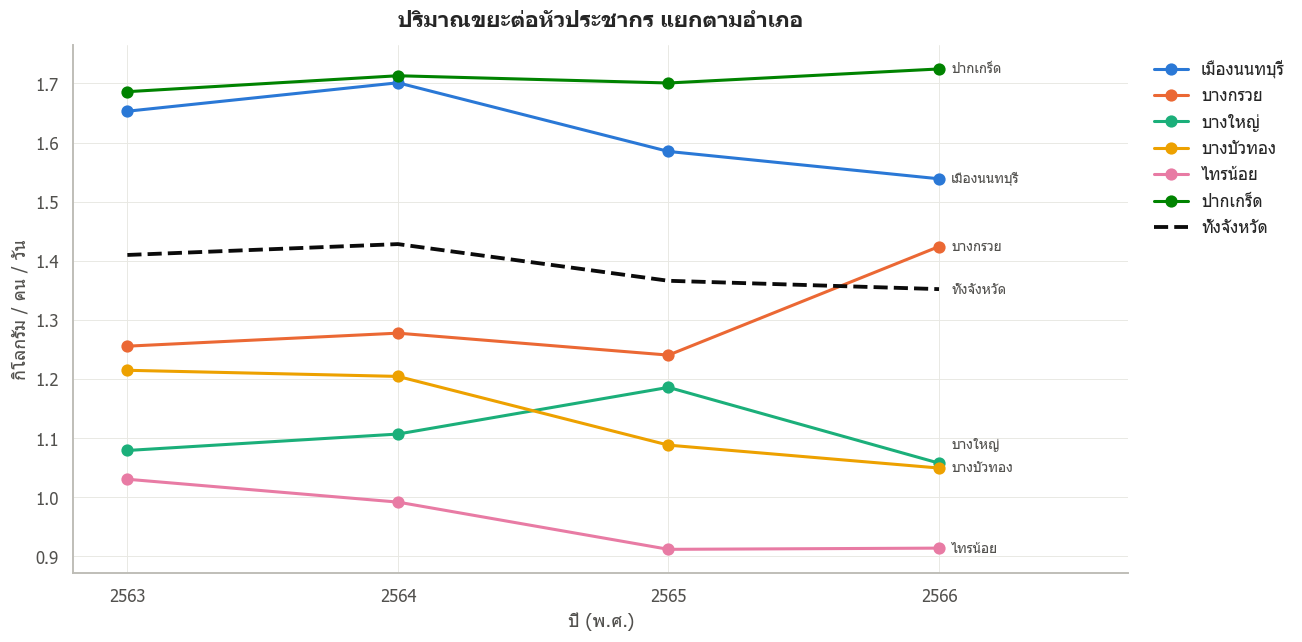

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด,ทั้งจังหวัด
ปี,,,,,,,
2563,1.65,1.26,1.08,1.21,1.03,1.69,1.41
2564,1.70,1.28,1.11,1.20,0.99,1.71,1.43
2565,1.58,1.24,1.19,1.09,0.91,1.70,1.37
2566,1.54,1.42,1.06,1.05,0.91,1.72,1.35


In [32]:
pop = pd.read_csv('../data/clean/clean_population.csv')
pop = pop[pop['อำเภอ'] != 'รวมยอด'].copy()
pop['อำเภอ'] = pop['อำเภอ'].str.replace('อำเภอ', '', n=1)
pop_long = (pop.melt(id_vars='อำเภอ', value_vars=[c for c in pop.columns if c.startswith('ประชากร_')],
                     var_name='ปี', value_name='ประชากร')
               .assign(ปี=lambda d: d['ปี'].str[-4:].astype(int)))
waste_dy = viz.groupby(['อำเภอ', 'ปี'])['ขยะมูลฝอยชุมชน(ตัน)'].sum().reset_index()
per_cap = waste_dy.merge(pop_long, on=['อำเภอ', 'ปี'])
per_cap['กก./คน/วัน'] = per_cap['ขยะมูลฝอยชุมชน(ตัน)'] * 1000 / per_cap['ประชากร'] / 365
pc = per_cap.pivot(index='ปี', columns='อำเภอ', values='กก./คน/วัน')[[d for d in DIST_ORDER]]

prov = per_cap.groupby('ปี')[['ขยะมูลฝอยชุมชน(ตัน)', 'ประชากร']].sum()
prov_pc = prov['ขยะมูลฝอยชุมชน(ตัน)'] * 1000 / prov['ประชากร'] / 365

fig, ax = plt.subplots(figsize=(12, 6))
for d in pc.columns:
    ax.plot(pc.index, pc[d], marker='o', markersize=7, linewidth=2, color=DIST_COLOR[d], label=d)
ax.plot(prov_pc.index, prov_pc.values, color='#0b0b0b', linewidth=2.5, linestyle='--', label='ทั้งจังหวัด')
ax.set_xticks(pc.index)
ax.set_xlim(pc.index.min() - 0.2, pc.index.max() + 0.7)
end_labels(ax, pc.index[-1], [(d, pc[d].iloc[-1]) for d in pc.columns] + [('ทั้งจังหวัด', prov_pc.iloc[-1])])
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ปริมาณขยะต่อหัวประชากร แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('กิโลกรัม / คน / วัน')
plt.tight_layout(); plt.show()
pc.assign(ทั้งจังหวัด=prov_pc).round(2)

---
## Key Findings

1. **Municipal solid waste is ~580,000–670,000 tonnes/year**, peaking in 2564 (2021, ~671,800 tonnes) and dropping clearly in 2567 (2024, ~579,600 tonnes, −10%) — the drop comes mainly from Mueang Nonthaburi (every month of 2567 is around 12,000–14,000 tonnes vs ~18,000 tonnes in 2566)
2. **Mueang Nonthaburi (31.8%) and Pak Kret (24.7%) together produce more than half of the province's waste**, and the top 10 local governments account for ~67% (Nonthaburi City Municipality 24.4%, Pak Kret City Municipality 20.3%)
3. **There is no clear seasonality** — every month is around 7.8–8.6% of the total. April looks lowest, but partly because **April 2566 in Mueang Nonthaburi is abnormally low (~4,100 tonnes vs ~18,000 tonnes in other months)**, which is probably missing data (visible as a dip in the monthly-by-district line chart). Check this before drawing conclusions about seasonality
4. **Province-wide waste per person is ~1.35–1.43 kg/person/day**, above the national average, with Pak Kret (~1.7) and Mueang Nonthaburi (~1.5–1.7) the highest — likely due to an unregistered daytime population (workers/shopping malls/government offices) — and Sai Noi the lowest (~0.9)

## สรุปข้อค้นพบ

1. **ขยะมูลฝอยชุมชน ~580,000–670,000 ตัน/ปี** สูงสุดปี 2564 (~671,800 ตัน) และลดลงชัดเจนในปี 2567 (~579,600 ตัน, −10%) — ส่วนที่ลดมาจากอำเภอเมืองนนทบุรีเป็นหลัก (ทุกเดือนของปี 2567 อยู่ราว 12,000–14,000 ตัน เทียบกับ ~18,000 ตันในปี 2566)
2. **อำเภอเมืองนนทบุรี (31.8%) และปากเกร็ด (24.7%) รวมกันมีขยะเกินครึ่งจังหวัด** และ 10 อปท. แรกครองสัดส่วน ~67% (เทศบาลนครนนทบุรี 24.4%, เทศบาลนครปากเกร็ด 20.3%)
3. **ไม่มีฤดูกาลที่ชัดเจน** — ทุกเดือนอยู่ราว 7.8–8.6% ของยอดรวม เดือนเมษายนดูต่ำสุด แต่ส่วนหนึ่งเป็นเพราะ **เมษายน 2566 ของอำเภอเมืองนนทบุรีมีค่าต่ำผิดปกติ (~4,100 ตัน เทียบกับ ~18,000 ตันในเดือนอื่น)** ซึ่งน่าจะเป็นข้อมูลขาด (เห็นเป็นจุดดิ่งในกราฟเส้นรายเดือนแยกอำเภอ) ควรตรวจสอบก่อนสรุปเรื่องฤดูกาล
4. **ขยะต่อหัวทั้งจังหวัด ~1.35–1.43 กก./คน/วัน** สูงกว่าค่าเฉลี่ยประเทศ โดยปากเกร็ด (~1.7) และเมืองนนทบุรี (~1.5–1.7) สูงสุด — น่าจะมีประชากรแฝง (คนทำงาน/ห้าง/สถานที่ราชการ) ส่วนไทรน้อยต่ำสุด (~0.9)